# 11 · Design Effectiveness: Was the experiment fair?

**Author:** Pariya

Before we trust the completion-rate result, we check that the Control and Test groups are comparable. If the groups were very different (for example, much older clients in one group), the difference in completion could come from the clients, not from the new design.

For every test we use a significance level of **α = 0.05**:
- p-value < 0.05 → we reject the null hypothesis
- p-value > 0.05 → we are not able to reject the null hypothesis

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats



## Load the data

The data is ready: 50,488 clients, Test 26,961 and Control 23,527.

In [2]:
clients_demo = pd.read_csv('cleaned_clients_demographics.csv')
clients_var = pd.read_csv('cleaned_clients_variation.csv')

clients_var = clients_var.rename(columns={'Variation': 'variation'})
df_clients = clients_var.merge(clients_demo, on='client_id', how='inner')

print(df_clients.shape)
print(df_clients['variation'].value_counts())

(50488, 10)
variation
Test       26961
Control    23527
Name: count, dtype: int64


## Step 1: Were clients split 50/50 between the groups?

If the website randomly put each client in Control or Test with a 50% chance, we'd expect about half in each group:

50,488 / 2 = 25,244 per group

We observed 26,961 and 23,527. The question is whether that difference is just random variation or too big to be chance.

**Test:** chi-square goodness-of-fit test (`stats.chisquare()`). It compares the observed counts with the expected counts.

**Hypotheses:**
- H₀: Clients were split 50/50 (the difference is due to chance).
- H₁: The split is not 50/50.

In [3]:
alpha = 0.05

# Observed number of clients per group
observed = df_clients['variation'].value_counts()
print("Observed:\n", observed)

# Expected number per group if the split were 50/50
total = observed.sum()
expected = [total / 2, total / 2]
print("Expected per group:", total / 2)

# Share of each group
print("\nShare (%):\n", (observed / total * 100).round(1))

# Chi-square goodness-of-fit test
chi2_stat, p_value_split = stats.chisquare(f_obs=observed, f_exp=expected)
print(f"\nChi-square statistic: {chi2_stat:.2f}")
print(f"p-value: {p_value_split:.2e}")

if p_value_split > alpha:
    print("  We are not able to reject the null hypothesis")
else:
    print("  We reject the null hypothesis")

Observed:
 variation
Test       26961
Control    23527
Name: count, dtype: int64
Expected per group: 25244.0

Share (%):
 variation
Test       53.4
Control    46.6
Name: count, dtype: float64

Chi-square statistic: 233.57
p-value: 9.94e-53
  We reject the null hypothesis


**Result:** p < 0.001, so **we reject the null hypothesis**. The split is not 50/50: Test has 26,961 clients (53.4%) and Control has 23,527 (46.6%).

This may have been intentional, but if not, it could point to a problem with how clients were assigned. The next steps check whether the two groups are still similar in age, tenure, balance and gender.

## Step 2: Are Control and Test similar in age and tenure?

Age and tenure are numbers, and we compare the average of two different groups of clients, so the test is the **independent t-test** (`stats.ttest_ind()`). We use `equal_var=False` (Welch's t-test), so we don't assume both groups have the same spread.

**Hypotheses (for age, and the same for tenure):**
- H₀: μ_test = μ_control (Control and Test have the same average age)
- H₁: μ_test ≠ μ_control (the averages are different)

Here we hope for a high p-value (above 0.05), because that would mean the groups are similar, so the experiment is fair.

In [4]:
control = df_clients[df_clients['variation'] == 'Control']
test = df_clients[df_clients['variation'] == 'Test']

t_stat_age, p_value_age = stats.ttest_ind(test['clnt_age'], control['clnt_age'], equal_var=False)

print("Age")
print(f"  Control mean: {control['clnt_age'].mean():.2f}")
print(f"  Test mean:    {test['clnt_age'].mean():.2f}")
print(f"  Difference:   {test['clnt_age'].mean() - control['clnt_age'].mean():.2f}")
print(f"  p-value:      {p_value_age:.4f}")

if p_value_age > alpha:
    print("  We are not able to reject the null hypothesis")
else:
    print("  We reject the null hypothesis")

Age
  Control mean: 47.50
  Test mean:    47.16
  Difference:   -0.33
  p-value:      0.0157
  We reject the null hypothesis


In [5]:
t_stat_tenure, p_value_tenure = stats.ttest_ind(test['clnt_tenure_yr'], control['clnt_tenure_yr'], equal_var=False)

print("Tenure")
print(f"  Control mean: {control['clnt_tenure_yr'].mean():.2f}")
print(f"  Test mean:    {test['clnt_tenure_yr'].mean():.2f}")
print(f"  Difference:   {test['clnt_tenure_yr'].mean() - control['clnt_tenure_yr'].mean():.2f}")
print(f"  p-value:      {p_value_tenure:.4f}")

if p_value_tenure > alpha:
    print("  We are not able to reject the null hypothesis")
else:
    print("  We reject the null hypothesis")

Tenure
  Control mean: 12.09
  Test mean:    11.98
  Difference:   -0.10
  p-value:      0.0870
  We are not able to reject the null hypothesis


**Age:** p = 0.016, which is below 0.05, so **we reject the null hypothesis**: the average age is statistically different. But the difference is very small: 47.5 years in Control and 47.2 in Test, only about 4 months. With about 50,000 clients, even tiny differences become statistically significant. In practice, the groups are comparable in age.

**Tenure:** p = 0.087, which is above 0.05, so **we are not able to reject the null hypothesis**. The average tenure is 12.1 years in Control and 12.0 years in Test, a difference of about 1 month. The groups are comparable in tenure.

## Age distribution: Control vs Test

The chart shows the share of clients at each age in both groups. The two lines almost overlap, which confirms what the t-test showed: the age difference between the groups is very small.

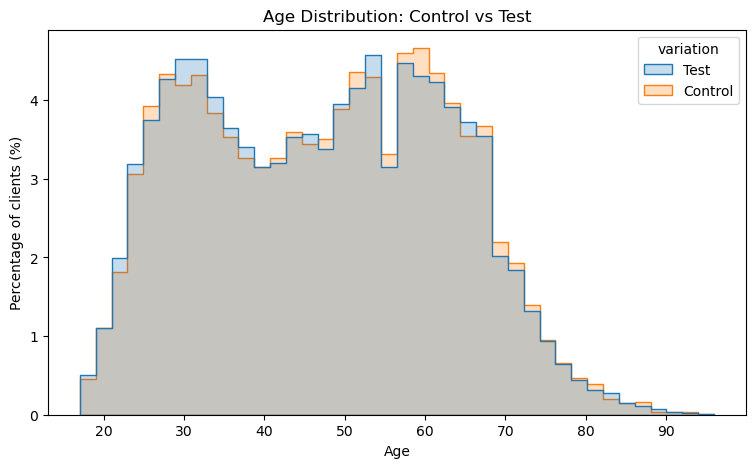

In [6]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clients, x='clnt_age', hue='variation',
             stat='percent', common_norm=False, element='step', bins=40)
plt.title('Age Distribution: Control vs Test')
plt.xlabel('Age')
plt.ylabel('Percentage of clients (%)')
plt.show()

## Step 3: Are Control and Test similar in balance?

Balance (`bal`) is a number, so we compare the average balance of the two groups with the **independent t-test** (`stats.ttest_ind()`).

Note: balance is very skewed. Most clients have a moderate balance and a few are very wealthy, so the mean (about 150,000) is much higher than the median (about 66,000). For this reason we also print the median, to see the typical client.

**Hypotheses:**
- H₀: μ_test = μ_control (Control and Test have the same average balance)
- H₁: μ_test ≠ μ_control (the average balances are different)

In [7]:
t_stat_bal, p_value_bal = stats.ttest_ind(test['bal'], control['bal'], equal_var=True)

print("Balance")
print(f"  Control mean:   {control['bal'].mean():,.0f}")
print(f"  Test mean:      {test['bal'].mean():,.0f}")
print(f"  Control median: {control['bal'].median():,.0f}")
print(f"  Test median:    {test['bal'].median():,.0f}")
print(f"  p-value:        {p_value_bal:.4f}")

if p_value_bal > alpha:
    print("  We are not able to reject the null hypothesis")
else:
    print("  We reject the null hypothesis")

Balance
  Control mean:   150,147
  Test mean:      148,963
  Control median: 66,024
  Test median:    65,468
  p-value:        0.6602
  We are not able to reject the null hypothesis


**Balance:** p = 0.66, which is above 0.05, so **we are not able to reject the null hypothesis**. The average balance is 150,147 in Control and 148,963 in Test, and the median is also very close (66,024 vs 65,468). The two groups are comparable in balance.

## Step 4: Are Control and Test similar in gender?

Gender is categorical (F / M / U) and we compare it across two groups. That's two categorical variables (group × gender), so the test is the **chi-square test of independence** (`stats.chi2_contingency()`).

**Hypotheses:**
- H₀: The gender mix is the same in Control and Test (gender is independent of the group).
- H₁: The gender mix differs between the groups.

In [8]:
# Table: number of clients per group and gender
gender_table = pd.crosstab(df_clients['variation'], df_clients['gendr'])
print(gender_table)

# Same table as percentages per group (each row adds up to 100%)
print()
print((pd.crosstab(df_clients['variation'], df_clients['gendr'], normalize='index') * 100).round(1))

# Chi-square test
chi2_stat, p_value_gender, dof, expected = stats.chi2_contingency(gender_table)
print(f"\np-value: {p_value_gender:.4f}")

if p_value_gender > alpha:
    print("  We are not able to reject the null hypothesis")
else:
    print("  We reject the null hypothesis")

gendr         F     M     U
variation                  
Control    7543  7970  8014
Test       8716  8977  9268

gendr         F     M     U
variation                  
Control    32.1  33.9  34.1
Test       32.3  33.3  34.4

p-value: 0.3877
  We are not able to reject the null hypothesis


**Gender:** p = 0.39, which is above 0.05, so **we are not able to reject the null hypothesis**. The gender mix is almost identical in both groups (about 32% F, 33–34% M and 34% U). The groups are comparable in gender.

## Step 5: Conclusion — Was the experiment fair?

| Check | Control | Test | p-value | Result |
|---|---|---|---|---|
| Group size | 46.6% | 53.4% | < 0.001 | Not 50/50 |
| Average age | 47.5 | 47.2 | 0.016 | Statistically different, but only ~4 months |
| Average tenure (years) | 12.1 | 12.0 | 0.087 | Comparable |
| Average balance | 150,147 | 148,963 | 0.66 | Comparable |
| Gender (F / M / U) | 32 / 34 / 34% | 32 / 33 / 34% | 0.39 | Comparable |

The Test group is somewhat larger than the Control group (53% vs 47%), which may or may not have been planned. However, the two groups are very similar in age, tenure, balance and gender. The only statistically significant difference (age) is too small to matter in practice. This means the clients in both groups are comparable, so the higher completion rate in the Test group can be attributed to the new design rather than to differences between the clients.

**Recommendation:** In future experiments, Vanguard should check that clients are split evenly between the groups, or document the intended split in advance.